# Broken-bond snapshot

Run the first code cell to compare the initial bond count with `uniaxial-gpu.py`. The next cell shows the final broken-bond snapshot and 2D projections. The last cell plots broken-bond counts by distance from the box center.

In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Find this simulation's inputs no matter which of the two folders is the cwd.
PROJECT_DIR = next(
    (p.resolve() for p in (Path.cwd(), Path.cwd() / 'ideal-chains') if (p / 'connected_xlinks.txt').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not locate ideal-chains/connected_xlinks.txt')
OUTPUT_DIR = PROJECT_DIR / 'output-gpu'

# Same count rule as bond_entries()/count_bonds() in this folder's uniaxial-gpu.py.
def count_bonds(connections, n_positions):
    source = connections[:, :1]
    neighbors = connections[:, 1:]
    source_ids = np.broadcast_to(source, neighbors.shape)
    valid = (
        (source_ids >= 0)
        & (source_ids < n_positions)
        & (neighbors >= 0)
        & (neighbors < n_positions)
        & (neighbors != source_ids)
    )
    return int(np.count_nonzero(valid))


def legacy_count_bonds(connections):
    # Reproduce the old implementation to show where 272666 came from.
    bonds = set()
    for i in range(len(connections)):
        for k in range(connections.shape[1]):
            value = connections[i, k]
            if value != -1 and value != i:
                bonds.add(tuple(sorted((i, int(value)))))
    return len(bonds)


positions_initial = np.loadtxt(PROJECT_DIR / 'crosslinks-positions.txt')
initial_connections = np.loadtxt(
    PROJECT_DIR / 'connected_xlinks.txt', skiprows=1, delimiter='\t', dtype=np.int64
) - 1
if initial_connections.ndim == 1:
    initial_connections = initial_connections.reshape(1, -1)

step1_connections = np.loadtxt(OUTPUT_DIR / 'step_0001' / 'connections.txt', delimiter='\t', dtype=np.int64)
if step1_connections.ndim == 1:
    step1_connections = step1_connections.reshape(1, -1)

initial_bonds = count_bonds(initial_connections, len(positions_initial))
step1_bonds = count_bonds(step1_connections, len(positions_initial))
legacy_bonds = legacy_count_bonds(initial_connections)
source_id_mismatches = int(np.count_nonzero(initial_connections[:, 0] != np.arange(len(initial_connections))))
print(f'Old count_bonds() result (reproduced): {legacy_bonds:,}')
print(f'Rows where source ID differs from row number: {source_id_mismatches:,} / {len(initial_connections):,}')
print(f'Correct valid directed bond entries: {initial_bonds:,}')
print(f'Initial bond entries (same rule as uniaxial-gpu.py): {initial_bonds:,}')
print(f'Initial step_0001 bond entries: {step1_bonds:,}')
print(f'Input and step_0001 counts match: {initial_bonds == step1_bonds}')

# Show what the saved run summary recorded; it may use an older count rule.
summary_path = OUTPUT_DIR / 'step_0001' / 'summary.txt'
summary_bonds = None
for line in summary_path.read_text().splitlines():
    if line.startswith('Remaining bonds:'):
        summary_bonds = line.split(':', 1)[1].strip()
        break
print(f'Saved step_0001 summary: {summary_bonds}')
if summary_bonds:
    recorded_initial = int(summary_bonds.split('/')[-1])
    print(f'Saved summary agrees with the current count rule: {recorded_initial == initial_bonds}')


Old count_bonds() result (reproduced): 272,666
Rows where source ID differs from row number: 58,000 / 80,657
Correct valid directed bond entries: 227,010
Initial bond entries (same rule as uniaxial-gpu.py): 227,010
Initial step_0001 bond entries: 227,010
Input and step_0001 counts match: True
Saved step_0001 summary: 227010/227010
Saved summary agrees with the current count rule: True


Broken physical connections in step_final: 108
Reciprocal adjacency entries removed: 216


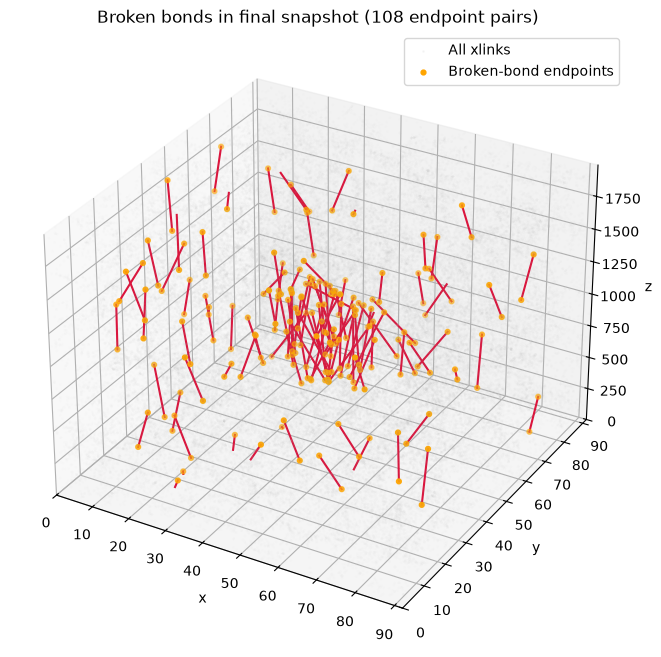

In [ ]:
# Compare the initial connection table with the final saved state.
final_connections = np.loadtxt(OUTPUT_DIR / 'step_final' / 'connections.txt', delimiter='\t', dtype=np.int64)
final_positions = np.loadtxt(OUTPUT_DIR / 'step_final' / 'positions.txt')
box = np.atleast_1d(np.loadtxt(OUTPUT_DIR / 'step_final' / 'box.txt'))
if final_connections.ndim == 1:
    final_connections = final_connections.reshape(1, -1)
if not np.array_equal(initial_connections[:, 0], final_connections[:, 0]):
    raise ValueError('Initial and final connection source IDs differ')

source_ids = np.broadcast_to(initial_connections[:, :1], initial_connections[:, 1:].shape)
initial_neighbors = initial_connections[:, 1:]
final_neighbors = final_connections[:, 1:]
removed_slots = (initial_neighbors >= 0) & (final_neighbors == -1)
# Select one of each reciprocal pair; repeated parallel slots remain separate.
broken_slots = removed_slots & (source_ids < initial_neighbors)
broken_edges = np.column_stack((source_ids[broken_slots], initial_neighbors[broken_slots])).astype(int)
directed_removed = int(removed_slots.sum())
print(f'Broken physical connections in step_final: {len(broken_edges):,}')
print(f'Reciprocal adjacency entries removed: {directed_removed:,}')
if directed_removed != 2 * len(broken_edges):
    print('Warning: not every broken connection has exactly two reciprocal entries.')

# Draw a single line per endpoint pair so parallel bonds do not obscure one another.
plot_edges = np.unique(broken_edges, axis=0)
broken_nodes = np.unique(plot_edges) if len(plot_edges) else np.array([], dtype=int)
wrapped_positions = np.mod(final_positions, box)


def periodic_segments(start, delta, box):
    crossing_times = [0.0, 1.0]
    end = start + delta
    for axis in range(3):
        if delta[axis] > 0 and end[axis] >= box[axis]:
            crossing_times.append((box[axis] - start[axis]) / delta[axis])
        elif delta[axis] < 0 and end[axis] < 0:
            crossing_times.append(-start[axis] / delta[axis])
    crossing_times = sorted(set(crossing_times))
    for left, right in zip(crossing_times[:-1], crossing_times[1:]):
        midpoint = start + ((left + right) / 2) * delta
        offset = np.floor(midpoint / box) * box
        yield start + left * delta - offset, start + right * delta - offset

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(
    wrapped_positions[:, 0], wrapped_positions[:, 1], wrapped_positions[:, 2],
    s=1, color='lightgray', alpha=0.15, label='All xlinks',
)
for i, j in plot_edges:
    start = wrapped_positions[i]
    delta = wrapped_positions[j] - start
    delta = (delta + box / 2) % box - box / 2
    for segment_start, segment_end in periodic_segments(start, delta, box):
        ax.plot(
            [segment_start[0], segment_end[0]],
            [segment_start[1], segment_end[1]],
            [segment_start[2], segment_end[2]],
            color='crimson', linewidth=1.5,
        )
if len(broken_nodes):
    points = wrapped_positions[broken_nodes]
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=12, color='orange', label='Broken-bond endpoints')
ax.set_xlim(0, box[0])
ax.set_ylim(0, box[1])
ax.set_zlim(0, box[2])
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title(f'Broken bonds in final snapshot ({len(plot_edges)} endpoint pairs)')
ax.legend()
plt.show()

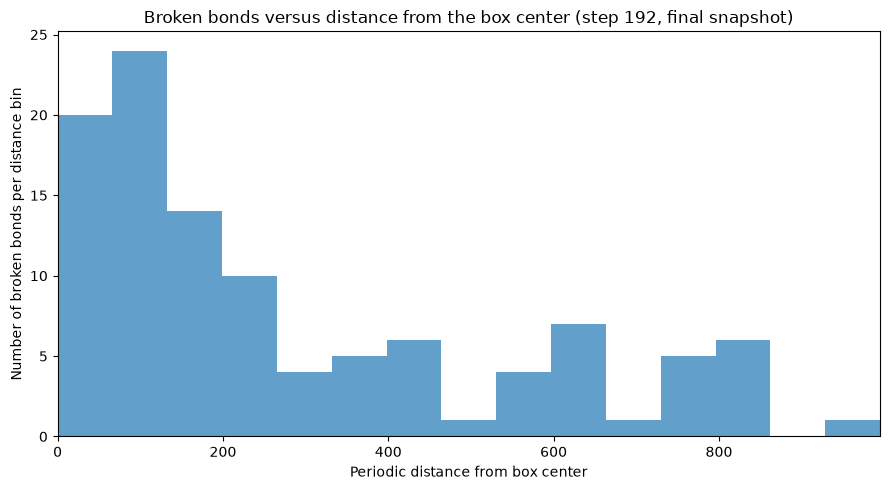

Total initial physical bond instances: 113,505
Total broken physical bond instances: 108


In [13]:
# Count broken bonds by their periodic distance from the box center.
# Reciprocal entries represent one physical bond; duplicate bonds remain separate.

#2D projections: color each bin by the fraction of its initial bond instances
# that broke. This controls for regions that simply started with more bonds.
all_neighbors = initial_connections[:, 1:]
all_sources = np.broadcast_to(initial_connections[:, :1], all_neighbors.shape)
all_valid = (
    (all_sources >= 0)
    & (all_sources < len(final_positions))
    & (all_neighbors >= 0)
    & (all_neighbors < len(final_positions))
    & (all_neighbors != all_sources)
    & (all_sources < all_neighbors)
)
all_edges = np.column_stack((all_sources[all_valid], all_neighbors[all_valid])).astype(int)

def bond_midpoints(edges):
    starts = final_positions[edges[:, 0]]
    deltas = final_positions[edges[:, 1]] - starts
    deltas = (deltas + box / 2) % box - box / 2
    return (starts + deltas / 2) % box

all_midpoints = bond_midpoints(all_edges)
broken_midpoints = bond_midpoints(broken_edges)




center = box / 2
maximum_distance = np.linalg.norm(center)
radial_bins = 15
radial_edges = np.linspace(0, maximum_distance, radial_bins + 1)

def periodic_distance_from_center(midpoints):
    displacement = (midpoints - center + box / 2) % box - box / 2
    return np.linalg.norm(displacement, axis=1)

broken_distances = periodic_distance_from_center(broken_midpoints)
broken_per_bin, _ = np.histogram(broken_distances, bins=radial_edges)
radial_centers = (radial_edges[:-1] + radial_edges[1:]) / 2
bin_widths = np.diff(radial_edges)

fig, count_ax = plt.subplots(figsize=(9, 5))
count_ax.bar(
    radial_centers,
    broken_per_bin,
    width=bin_widths,
    alpha=0.7
)
count_ax.set_xlabel('Periodic distance from box center')
count_ax.set_ylabel('Number of broken bonds per distance bin')
count_ax.set_xlim(0, maximum_distance)

count_ax.set_title('Broken bonds versus distance from the box center (step 192, final snapshot)')
fig.tight_layout()
plt.show()

print(f'Total initial physical bond instances: {len(all_midpoints):,}')
print(f'Total broken physical bond instances: {len(broken_midpoints):,}')


In [5]:
import numpy as np

data_before = np.loadtxt("chain_bond_lengths.txt", skiprows=1)
data_after = np.loadtxt("/home/fernando/projects/networks/excluded-volume/output-gpu/chain_bond_lengths.txt", skiprows=1)

lengths_before = data_before[:, 3]
lengths_after = data_after[:, 3]

avg_before = np.average(lengths_before)
avg_after = np.average(lengths_after)

print(f"Average bond length before: {avg_before}"
      )
print(f"Average bond length after: {avg_after}"
      )

Average bond length before: 8.371714928501657
Average bond length after: 4.313051934559746
